# What is Regularization?

Regularization একটি technique, যার মাধ্যমে Model-এর Complexity নিয়ন্ত্রণ করে Overfitting কমানোর চেষ্টা করা হয়। Regularization model-কে training data মুখস্থ করা থেকে বিরত রাখে, যাতে নতুন বা unseen data-তেও ভালো prediction করতে পারে।

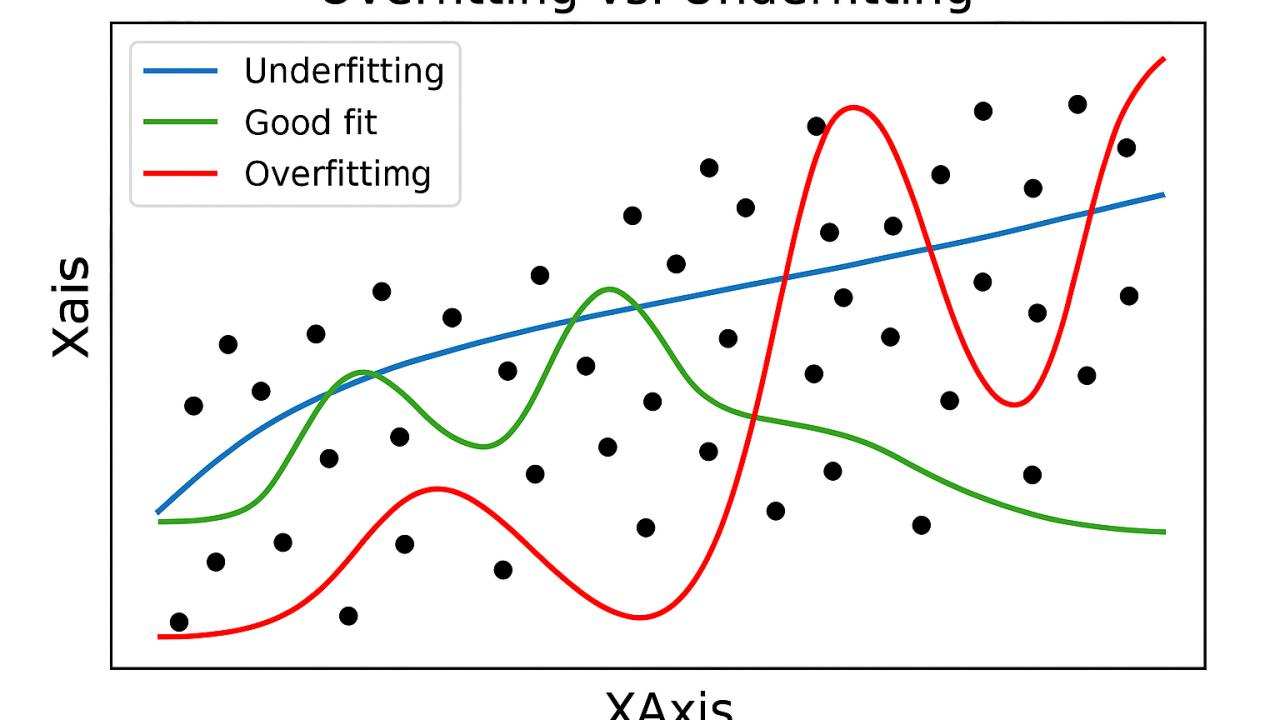

#  কেন Regularization প্রয়োজন?

একটি Neural Network train করলে।
- Training Accuracy = 99%
- Validation Accuracy = 75%
এখানে model training data-তে খুব ভালো করছে, কিন্তু নতুন data-তে ভালো করতে পারছে না।

এটিই Overfitting-এর লক্ষণ।

# Types of Reguralization

Deep Learning-এর জনপ্রিয় Regularization Techniques
প্রধান কয়েকটি technique হলো:
1. L1 Regularization (Lasso)
2. L2 Regularization (Ridge / Weight Decay)
3. Dropout

# Regularization কীভাবে কাজ করে?

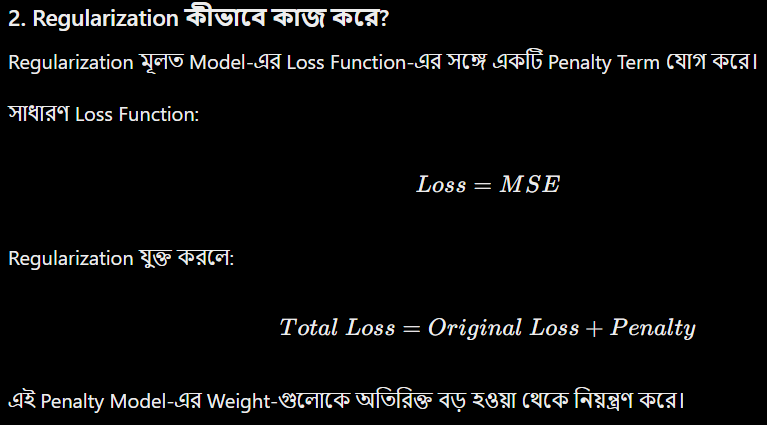
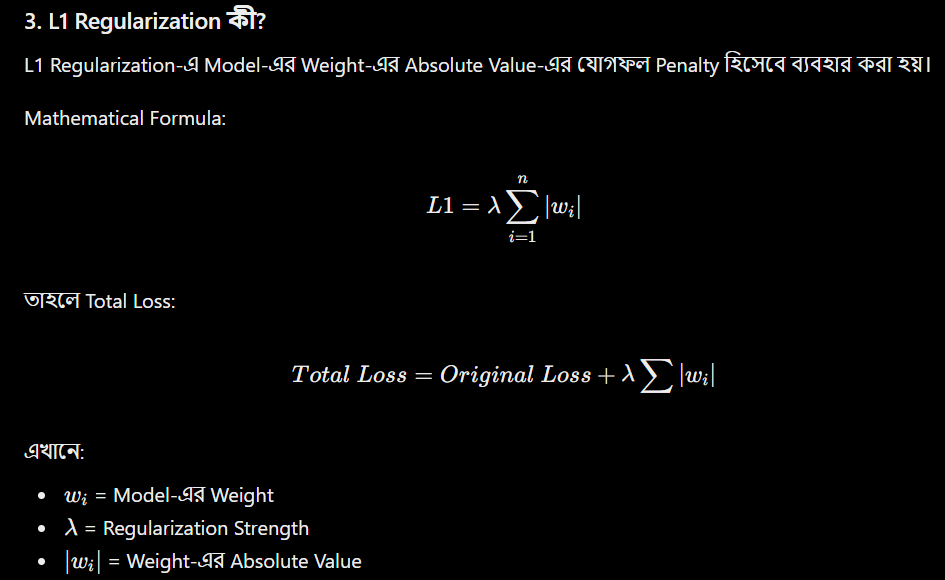

# What is L1?

L1 Regularization অনেক Weight-কে শূন্য (0) করে দিতে পারে।

ধরো, 
- Training-এর আগে Model-এর Weight: [0.9, 0.7, 0.5, 0.3, 0.1]
- L1 Regularization প্রয়োগের পর উদাহরণস্বরূপ: [0.6, 0.4, 0.0, 0.0, 0.0]

এখানে কিছু Weight শূন্য হয়ে গেছে।

এজন্য L1-কে Feature Selection-এর সঙ্গেও সম্পর্কিত করা হয়।
অর্থাৎ Model কিছু কম গুরুত্বপূর্ণ Feature-এর ওপর নির্ভরতা কমিয়ে দিতে পারে।

# What is L2 Regularization? 

L2 Regularization-এ Model-এর Weight-এর Square-এর যোগফল Penalty হিসেবে ব্যবহার করা হয়।

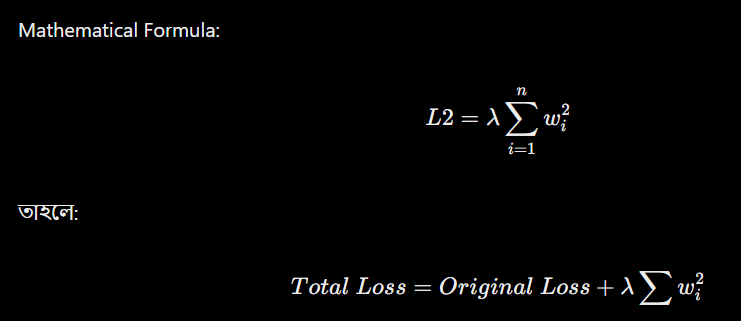

L2 Regularization Weight-গুলোকে ছোট করার চেষ্টা করে, কিন্তু সাধারণত একদম শূন্য করে না।

ধরো, 
- Training-এর আগে Model-এর Weight: [0.9, 0.7, 0.5, 0.3, 0.1]
- L2 Regularization প্রয়োগের পর উদাহরণস্বরূপ: [0.6, 0.5, 0.3, 0.2, 0.08]

এখানে Weight-গুলো ছোট হয়েছে, কিন্তু শূন্য হয়নি।

এজন্য L2-কে Weight Decay-এর সঙ্গেও সম্পর্কিত করা হয়।

# Model Apply

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from mlxtend.plotting import plot_decision_regions

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [2]:
X,y = make_moons(100, noise=0.25, random_state=2)

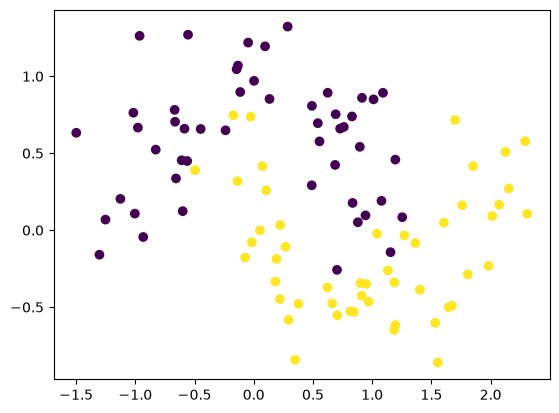

In [6]:
plt.scatter(x = X[:,0], y = X[:,1], c=y)
plt.show()

In [8]:
model1 = Sequential()

model1.add(Input(shape=(2,)))
model1.add(Dense(128,activation='relu'))
model1.add(Dense(128,activation='relu'))
model1.add(Dense(1,activation='sigmoid'))
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
adam = Adam(learning_rate=0.01)
model1.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])
history = model1.fit(X,y, validation_split=0.2, epochs=2000, verbose=0)

In [12]:
class KerasClassifierWrapper:
    
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        probabilities = self.model.predict(
            X, verbose=0
        )

        return (probabilities.ravel() > 0.5).astype(int)

clf = KerasClassifierWrapper(model1)

<Axes: >

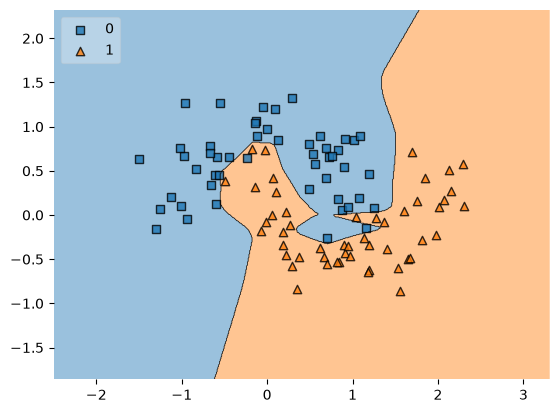

In [13]:
plot_decision_regions(X,y.astype('int'), clf=clf, legend=2)

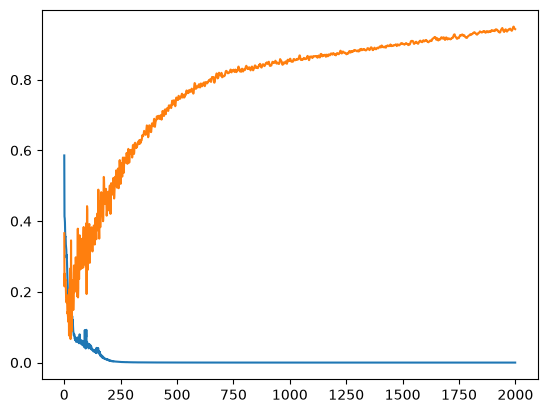

In [14]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

In [16]:
model2 = Sequential()

model2.add(Input(shape=(2,)))
model2.add(Dense(128, activation='relu', kernel_regularizer=tensorflow.keras.regularizers.l2(0.05)))
model2.add(Dense(128,activation='relu', kernel_regularizer=tensorflow.keras.regularizers.l2(0.05)))
model2.add(Dense(1,activation='sigmoid'))
model2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
adam = Adam(learning_rate=0.01)
model2.compile(loss='binary_crossentropy',optimizer=adam, metrics=['accuracy'])
history = model2.fit(X,y, validation_split=0.2, epochs=2000, verbose=0)

In [18]:
class KerasClassifierWrapper:
    
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        probabilities = self.model.predict(
            X, verbose=0
        )

        return (probabilities.ravel() > 0.5).astype(int)

clf = KerasClassifierWrapper(model2)

<Axes: >

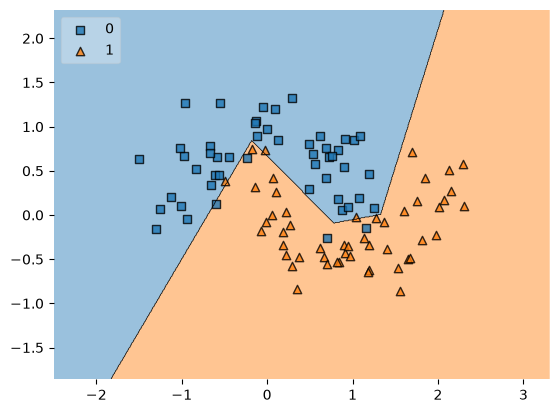

In [19]:
plot_decision_regions(X,y.astype('int'), clf=clf, legend=2)

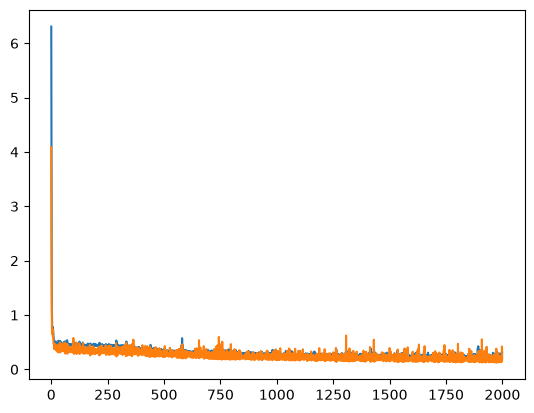

In [20]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])